# Laboratorium 3 — Dane obrazowe i wideo: potok i własny zbiór



## 0. Instalacja zależności

In [ ]:
!pip install torch torchvision matplotlib pandas

## Import bibliotek i wybór urządzenia

In [7]:
import os, shutil, zipfile
from collections import Counter
import numpy as np
import pandas as pd
import torch
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, Subset
from PIL import Image
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("wyniki", exist_ok=True)   # zapis wyników w folderze
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cu130 | torchvision: 0.26.0+cu130 | urządzenie: cuda


## 1. Własny zbiór: Apple-vs-Tomato



In [8]:
ZIP_PATH = "Apple-vs-Tomato.zip"
ROOT = "Apple-vs-Tomato"

if not os.path.isdir(ROOT):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(".")

# usunięcie katalogów technicznych, które ImageFolder potraktowałby jak klasy
for d, dirs, _ in os.walk(ROOT):
    for name in list(dirs):
        if name in {"__MACOSX", ".ipynb_checkpoints"}:
            shutil.rmtree(os.path.join(d, name)); dirs.remove(name)

print("Zbiór:", ROOT)
for c in sorted(os.listdir(ROOT)):
    print(f"  {c}: {len(os.listdir(os.path.join(ROOT, c)))} obrazów")

Zbiór: Apple-vs-Tomato
  Apples: 50 obrazów
  Tomatoes: 50 obrazów


## 2. Transformacje, ImageFolder, podział train/val i DataLoader

Dwa potoki: `eval_tf` (bez losowości) oraz `train_tf` (z augmentacją). Ponieważ zdjęcia leżą w jednym katalogu, tworzymy **dwa obiekty `ImageFolder`** (z różnymi transformacjami) i dzielimy je tym samym zestawem indeksów (`Subset`).

Podział jest **warstwowy** (po 80/20 w każdej klasie), powtarzalny (`seed=42`) i uwzględnia wykryte niemal identyczne obrazy - takie kopie trafiają zawsze do tej samej części, aby uniknąć wycieku danych.

In [9]:
IMG_SIZE = 64
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

ds_full = datasets.ImageFolder(ROOT)          # bez transformacji - tylko do podziału i statystyk
print("Klasy:", ds_full.classes, "-> indeksy:", ds_full.class_to_idx)
print("Liczba przykładów:", len(ds_full), "| na klasę:", dict(Counter(ds_full.targets)))

# wykrywanie niemal identycznych obrazów (miniatura 16x16, skala szarości, normalizacja)
def signature(path):
    a = np.asarray(Image.open(path).convert("L").resize((16, 16)), dtype=float)
    return (a - a.mean()) / (a.std() + 1e-6)

n = len(ds_full)
sigs = [signature(p) for p, _ in ds_full.samples]
dup_pairs = [(i, j) for i in range(n) for j in range(i + 1, n)
             if ds_full.targets[i] == ds_full.targets[j]
             and np.abs(sigs[i] - sigs[j]).mean() < 0.05]
print("Niemal identyczne pary:", [(os.path.basename(ds_full.samples[i][0]),
                                   os.path.basename(ds_full.samples[j][0])) for i, j in dup_pairs])

# podział warstwowy 80/20 z zachowaniem grup duplikatów
group = list(range(n))
for i, j in dup_pairs:
    group[j] = group[i]

rng = np.random.default_rng(42)               # powtarzalny podział
VAL_FRAC = 0.2
train_idx, val_idx = [], []
for cls in range(len(ds_full.classes)):
    units = {}
    for i in range(n):
        if ds_full.targets[i] == cls:
            units.setdefault(group[i], []).append(i)
    units = list(units.values())
    n_val = int(VAL_FRAC * sum(len(u) for u in units))
    val_c, train_c = [], []
    for k in rng.permutation(len(units)):
        u = units[k]
        (val_c if len(val_c) + len(u) <= n_val else train_c).extend(u)
    val_idx += val_c; train_idx += train_c
train_idx = rng.permutation(train_idx).tolist()
val_idx = rng.permutation(val_idx).tolist()
assert not set(train_idx) & set(val_idx), "wyciek: ten sam obraz w train i val"

train_full = datasets.ImageFolder(ROOT, transform=train_tf)
val_full = datasets.ImageFolder(ROOT, transform=eval_tf)
assert train_full.class_to_idx == val_full.class_to_idx == ds_full.class_to_idx
train_ds = Subset(train_full, train_idx)
val_ds = Subset(val_full, val_idx)

train_dl = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0)
val_dl = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=0)
print(f"train: {len(train_ds)} obrazów, {len(train_dl)} paczek | val: {len(val_ds)} obrazów, {len(val_dl)} paczek")

Klasy: ['Apples', 'Tomatoes'] -> indeksy: {'Apples': 0, 'Tomatoes': 1}
Liczba przykładów: 100 | na klasę: {0: 50, 1: 50}
Niemal identyczne pary: [('img_p1_29.jpeg', 'img_p1_68.jpeg')]
train: 80 obrazów, 5 paczek | val: 20 obrazów, 1 paczek


### Statystyki zbioru

In [10]:
rows = []
for k, name in enumerate(ds_full.classes):
    n_tr = sum(ds_full.targets[i] == k for i in train_idx)
    n_va = sum(ds_full.targets[i] == k for i in val_idx)
    rows.append({"klasa": name, "indeks": k, "train": n_tr, "val": n_va, "razem": n_tr + n_va})
stats = pd.DataFrame(rows)
print(stats.to_string(index=False))
print("\nLiczba klas:", len(ds_full.classes))
print("class_to_idx:", ds_full.class_to_idx)
print("Rozmiar tensora po transformacji (train):", tuple(train_ds[0][0].shape), "| (val):", tuple(val_ds[0][0].shape))
print("Balans całego zbioru (Counter):", Counter(ds_full.targets))

   klasa  indeks  train  val  razem
  Apples       0     40   10     50
Tomatoes       1     40   10     50

Liczba klas: 2
class_to_idx: {'Apples': 0, 'Tomatoes': 1}
Rozmiar tensora po transformacji (train): (3, 64, 64) | (val): (3, 64, 64)
Balans całego zbioru (Counter): Counter({0: 50, 1: 50})


## 3. Audyt jednej paczki

 Audytujemy paczkę treningową (z augmentacją, `shuffle=True`) oraz walidacyjną (bez augmentacji, `shuffle=False`).

[TRAIN (augmentacja)] kształt: (16, 3, 64, 64) | typ: torch.float32 | min: -1.000 | max: 1.000
[TRAIN (augmentacja)] etykiety: [0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0] | liczności: {0: 8, 1: 8}


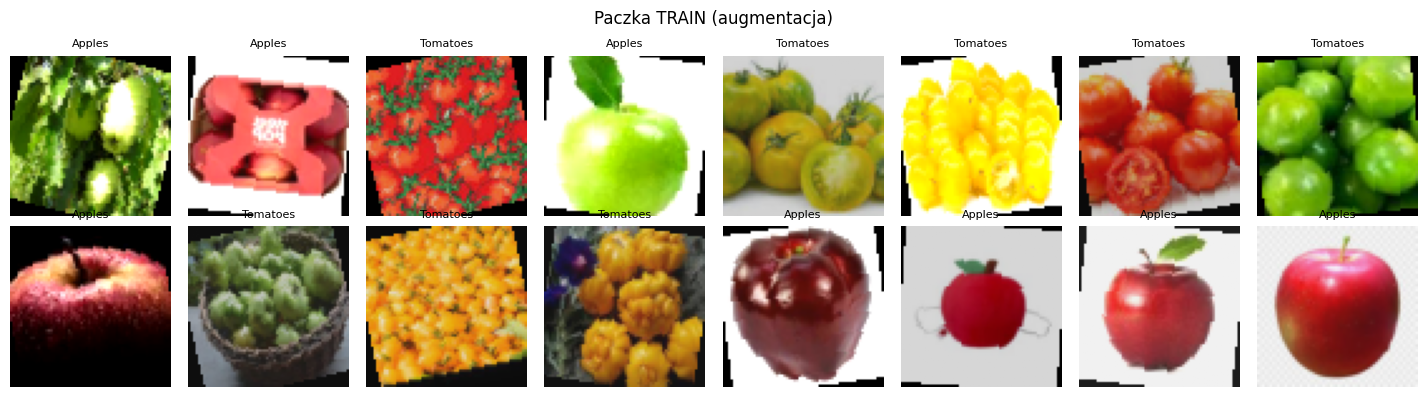

[VAL (bez augmentacji)] kształt: (20, 3, 64, 64) | typ: torch.float32 | min: -1.000 | max: 1.000
[VAL (bez augmentacji)] etykiety: [1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1] | liczności: {1: 10, 0: 10}


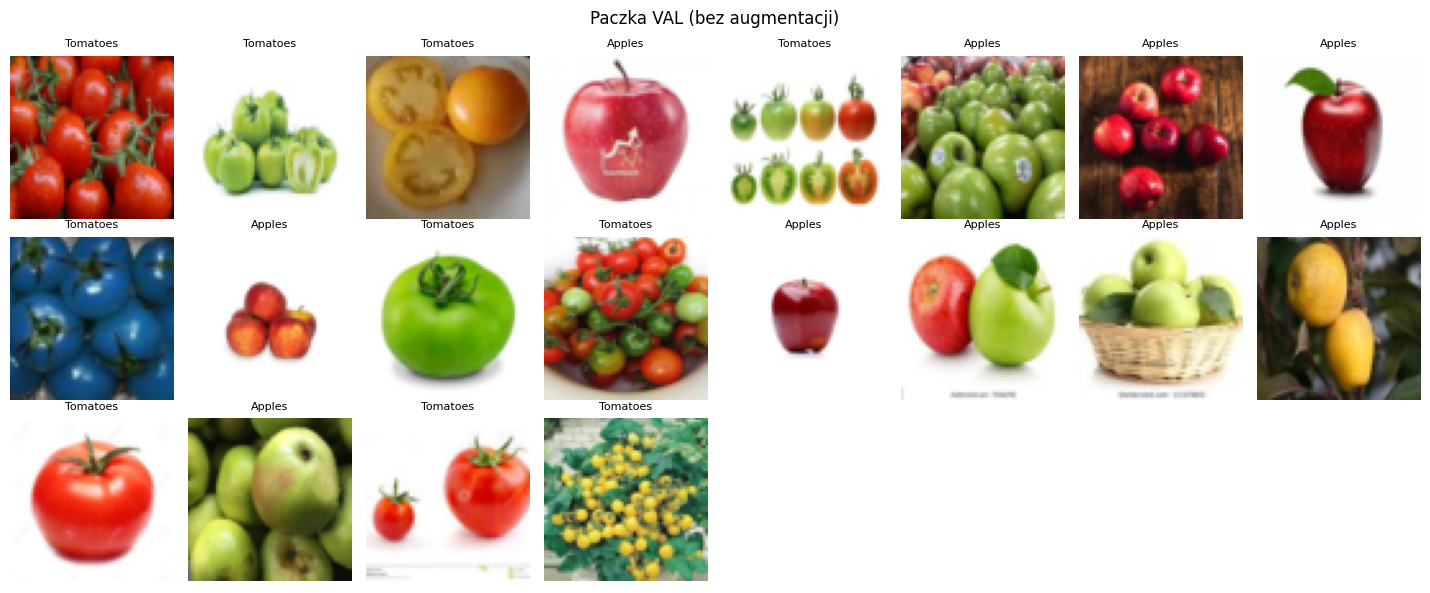

In [11]:
def show_batch(xb, yb, title, fname, ncols=8):
    nrows = int(np.ceil(len(xb) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(1.8 * ncols, 2.0 * nrows))
    for ax in axes.flat:
        ax.axis("off")
    for ax, img, lb in zip(axes.flat, xb, yb):
        ax.imshow((img * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy())   # odwrócenie normalizacji, CHW -> HWC
        ax.set_title(ds_full.classes[lb], fontsize=8)
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(f"wyniki/{fname}", dpi=120, bbox_inches="tight"); plt.show()

for name, loader, fname in [("TRAIN (augmentacja)", train_dl, "siatka_train.png"),
                            ("VAL (bez augmentacji)", val_dl, "siatka_val.png")]:
    xb, yb = next(iter(loader))
    print(f"[{name}] kształt: {tuple(xb.shape)} | typ: {xb.dtype} | min: {xb.min().item():.3f} | max: {xb.max().item():.3f}")
    print(f"[{name}] etykiety: {yb.tolist()} | liczności: {dict(Counter(yb.tolist()))}")
    show_batch(xb, yb, f"Paczka {name}", fname)

## 4. Podgląd wariantów augmentacji

Ta sama augmentacja zastosowana wielokrotnie do jednego obrazu daje różne warianty. Pokazujemy po jednym obrazie z każdej klasy (z części treningowej).

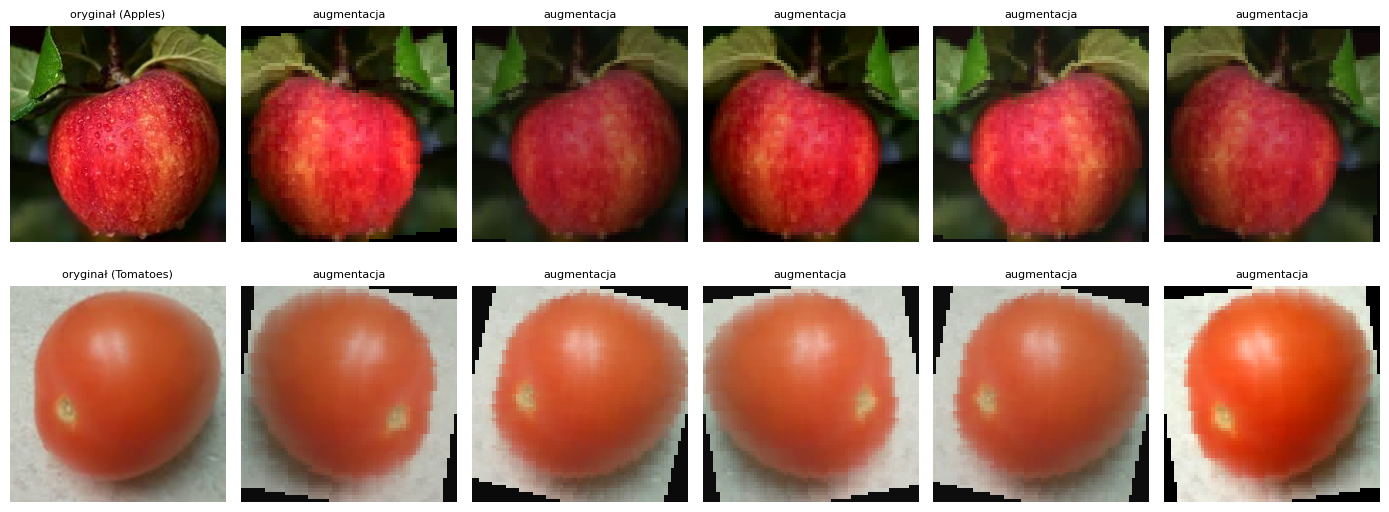

In [12]:
torch.manual_seed(0)
fig, axes = plt.subplots(len(ds_full.classes), 6, figsize=(14, 2.8 * len(ds_full.classes)))
for r, cls in enumerate(range(len(ds_full.classes))):
    i = next(i for i in train_idx if ds_full.targets[i] == cls)
    raw = Image.open(ds_full.samples[i][0]).convert("RGB")
    axes[r, 0].imshow(raw); axes[r, 0].set_title(f"oryginał ({ds_full.classes[cls]})", fontsize=8)
    for ax in axes[r, 1:]:
        aug = train_tf(raw)
        ax.imshow((aug * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()); ax.set_title("augmentacja", fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.savefig("wyniki/augmentacje.png", dpi=120, bbox_inches="tight"); plt.show()